In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import accuracy_score
from sklearn.metrics import confusion_matrix
from sklearn.metrics import classification_report


In [6]:
df = pd.read_csv("indian_engineering_placement_2026.csv")

In [7]:
df.head()

,Student_ID,Age,Gender,State,Branch,College_Tier,CGPA,Attendance_Percentage,DSA_Problems_Solved,Aptitude_Score,...,GitHub_Contributions,LinkedIn_Activity_Score,Hackathons_Participated,Competitive_Programming_Rating,Study_Hours_Per_Week,Soft_Skills_Score,Leadership_Experience,Extracurricular_Activities,Placement_Status,Package_LPA
0,ST00001,22,Male,Tamil Nadu,Mechanical,Tier-3,6.25,67.07,54,25,...,129,56.0,2,632,11,62,No,2,Not Placed,0.00
1,ST00002,21,Male,Uttar Pradesh,Mechanical,Tier-3,7.53,87.69,115,49,...,221,0.0,1,697,9,39,No,4,Not Placed,0.00
2,ST00003,23,Male,Jharkhand,IT,Tier-3,7.90,82.78,268,47,...,796,36.0,5,1850,41,55,No,1,Placed,6.87
3,ST00004,22,Female,Maharashtra,CSE,Tier-3,7.00,67.11,163,27,...,1077,47.0,2,1236,34,60,Yes,2,Placed,10.47
4,ST00005,19,Male,Maharashtra,AIML,Tier-2,6.23,78.93,221,24,...,442,42.0,4,1314,14,61,No,2,Placed,9.17


In [8]:
df.shape

(15000, 25)

In [9]:
df.columns

Index(['Student_ID', 'Age', 'Gender', 'State', 'Branch', 'College_Tier',
       'CGPA', 'Attendance_Percentage', 'DSA_Problems_Solved',
       'Aptitude_Score', 'Communication_Score', 'Projects_Count',
       'Internships_Count', 'Certifications_Count',
       'Open_Source_Contributions', 'GitHub_Contributions',
       'LinkedIn_Activity_Score', 'Hackathons_Participated',
       'Competitive_Programming_Rating', 'Study_Hours_Per_Week',
       'Soft_Skills_Score', 'Leadership_Experience',
       'Extracurricular_Activities', 'Placement_Status', 'Package_LPA'],
      dtype='object')

In [10]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15000 entries, 0 to 14999
Data columns (total 25 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   Student_ID                      15000 non-null  object 
 1   Age                             15000 non-null  int64  
 2   Gender                          15000 non-null  object 
 3   State                           15000 non-null  object 
 4   Branch                          15000 non-null  object 
 5   College_Tier                    15000 non-null  object 
 6   CGPA                            15000 non-null  float64
 7   Attendance_Percentage           15000 non-null  float64
 8   DSA_Problems_Solved             15000 non-null  int64  
 9   Aptitude_Score                  15000 non-null  int64  
 10  Communication_Score             15000 non-null  int64  
 11  Projects_Count                  15000 non-null  int64  
 12  Internships_Count               

In [11]:
df.describe()

,Age,CGPA,Attendance_Percentage,DSA_Problems_Solved,Aptitude_Score,Communication_Score,Projects_Count,Internships_Count,Certifications_Count,Open_Source_Contributions,GitHub_Contributions,LinkedIn_Activity_Score,Hackathons_Participated,Competitive_Programming_Rating,Study_Hours_Per_Week,Soft_Skills_Score,Extracurricular_Activities,Package_LPA
count,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000,14745.000000,15000.000000,14775.000000,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000
mean,21.153400,7.477432,73.774239,181.760667,39.993400,53.912333,3.514600,1.201267,3.499200,82.736792,506.151000,30.124196,2.206333,1121.632800,17.986733,52.239600,2.285933,6.547623
std,1.536324,0.870838,7.516522,83.611775,14.400763,15.731021,2.004708,1.131979,2.014978,63.965529,321.159554,18.463372,1.567096,533.458634,8.395494,11.150848,1.577236,7.273714
min,18.000000,4.050000,50.000000,12.000000,0.000000,0.000000,0.000000,0.000000,0.000000,8.000000,57.000000,0.000000,0.000000,126.000000,0.000000,15.000000,0.000000,0.000000
25%,20.000000,6.890000,68.660000,123.000000,30.000000,43.000000,2.000000,0.000000,2.000000,44.000000,291.000000,16.000000,1.000000,679.000000,12.000000,45.000000,1.000000,0.000000
50%,21.000000,7.470000,73.720000,176.000000,40.000000,54.000000,3.000000,1.000000,3.000000,65.000000,421.000000,29.000000,2.000000,912.000000,18.000000,52.000000,2.000000,5.940000
75%,22.000000,8.060000,78.810000,225.000000,49.000000,64.000000,5.000000,2.000000,5.000000,100.000000,637.000000,43.000000,3.000000,1585.000000,24.000000,60.000000,3.000000,10.170000
max,25.000000,10.000000,100.000000,1199.000000,99.000000,100.000000,14.000000,5.000000,15.000000,968.000000,4891.000000,100.000000,10.000000,2500.000000,50.000000,93.000000,10.000000,49.990000


In [12]:
df.isnull().sum()

Student_ID                          0
Age                                 0
Gender                              0
State                               0
Branch                              0
College_Tier                        0
CGPA                                0
Attendance_Percentage               0
DSA_Problems_Solved                 0
Aptitude_Score                      0
Communication_Score                 0
Projects_Count                      0
Internships_Count                   0
Certifications_Count                0
Open_Source_Contributions         255
GitHub_Contributions                0
LinkedIn_Activity_Score           225
Hackathons_Participated             0
Competitive_Programming_Rating      0
Study_Hours_Per_Week                0
Soft_Skills_Score                   0
Leadership_Experience               0
Extracurricular_Activities          0
Placement_Status                    0
Package_LPA                         0
dtype: int64

In [13]:
df.head()

,Student_ID,Age,Gender,State,Branch,College_Tier,CGPA,Attendance_Percentage,DSA_Problems_Solved,Aptitude_Score,...,GitHub_Contributions,LinkedIn_Activity_Score,Hackathons_Participated,Competitive_Programming_Rating,Study_Hours_Per_Week,Soft_Skills_Score,Leadership_Experience,Extracurricular_Activities,Placement_Status,Package_LPA
0,ST00001,22,Male,Tamil Nadu,Mechanical,Tier-3,6.25,67.07,54,25,...,129,56.0,2,632,11,62,No,2,Not Placed,0.00
1,ST00002,21,Male,Uttar Pradesh,Mechanical,Tier-3,7.53,87.69,115,49,...,221,0.0,1,697,9,39,No,4,Not Placed,0.00
2,ST00003,23,Male,Jharkhand,IT,Tier-3,7.90,82.78,268,47,...,796,36.0,5,1850,41,55,No,1,Placed,6.87
3,ST00004,22,Female,Maharashtra,CSE,Tier-3,7.00,67.11,163,27,...,1077,47.0,2,1236,34,60,Yes,2,Placed,10.47
4,ST00005,19,Male,Maharashtra,AIML,Tier-2,6.23,78.93,221,24,...,442,42.0,4,1314,14,61,No,2,Placed,9.17


In [14]:
df.duplicated().sum()

np.int64(0)

In [15]:
df.isnull().sum()

Student_ID                          0
Age                                 0
Gender                              0
State                               0
Branch                              0
College_Tier                        0
CGPA                                0
Attendance_Percentage               0
DSA_Problems_Solved                 0
Aptitude_Score                      0
Communication_Score                 0
Projects_Count                      0
Internships_Count                   0
Certifications_Count                0
Open_Source_Contributions         255
GitHub_Contributions                0
LinkedIn_Activity_Score           225
Hackathons_Participated             0
Competitive_Programming_Rating      0
Study_Hours_Per_Week                0
Soft_Skills_Score                   0
Leadership_Experience               0
Extracurricular_Activities          0
Placement_Status                    0
Package_LPA                         0
dtype: int64

In [16]:
df['Open_Source_Contributions'] = df['Open_Source_Contributions'].fillna(
    df['Open_Source_Contributions'].median()
)

df['LinkedIn_Activity_Score'] = df['LinkedIn_Activity_Score'].fillna(
    df['LinkedIn_Activity_Score'].median()
)

In [17]:
df.drop(['Student_ID', 'Package_LPA'], axis=1, inplace=True)

In [18]:
df.isnull().sum()

Age                               0
Gender                            0
State                             0
Branch                            0
College_Tier                      0
CGPA                              0
Attendance_Percentage             0
DSA_Problems_Solved               0
Aptitude_Score                    0
Communication_Score               0
Projects_Count                    0
Internships_Count                 0
Certifications_Count              0
Open_Source_Contributions         0
GitHub_Contributions              0
LinkedIn_Activity_Score           0
Hackathons_Participated           0
Competitive_Programming_Rating    0
Study_Hours_Per_Week              0
Soft_Skills_Score                 0
Leadership_Experience             0
Extracurricular_Activities        0
Placement_Status                  0
dtype: int64

In [19]:
df['Placement_Status'].value_counts()

Placement_Status
Placed        9770
Not Placed    5230
Name: count, dtype: int64

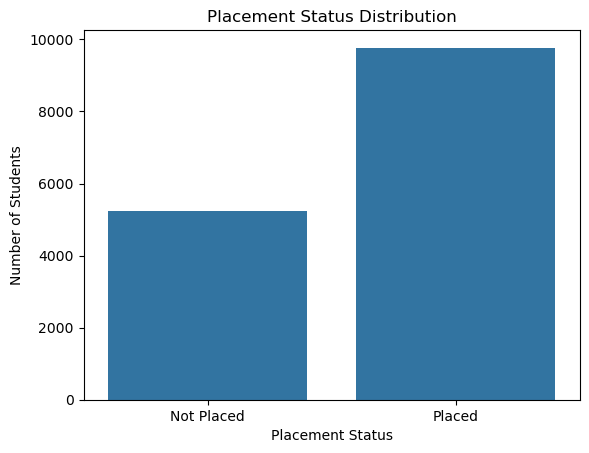

In [20]:
sns.countplot(x='Placement_Status', data=df)

plt.title('Placement Status Distribution')
plt.xlabel('Placement Status')
plt.ylabel('Number of Students')
plt.show()

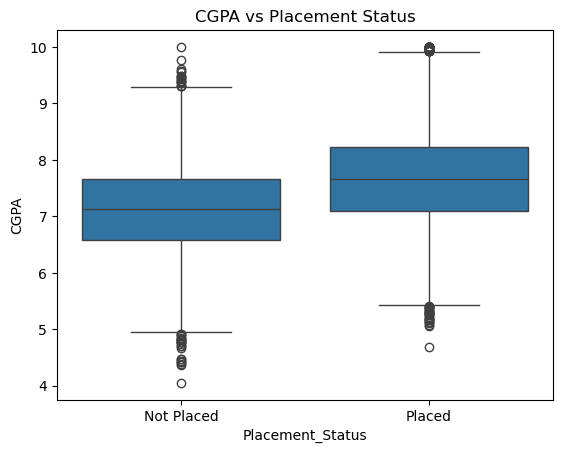

In [21]:
sns.boxplot(x='Placement_Status', y='CGPA', data=df)

plt.title('CGPA vs Placement Status')
plt.show()

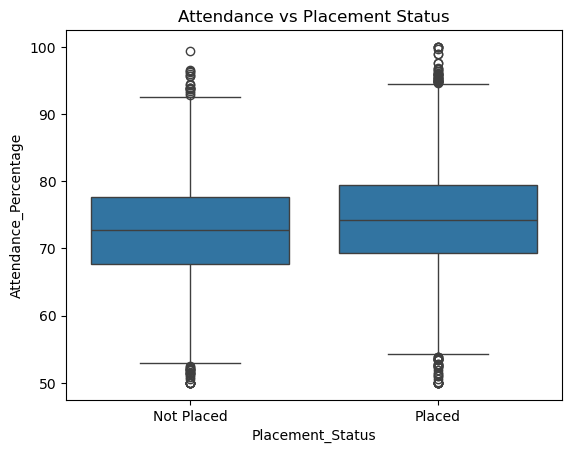

In [22]:
sns.boxplot(x='Placement_Status',
            y='Attendance_Percentage', data=df)

plt.title('Attendance vs Placement Status')
plt.show()

In [23]:
X = df.drop('Placement_Status', axis=1)

y = df['Placement_Status']

In [24]:
X.head()

,Age,Gender,State,Branch,College_Tier,CGPA,Attendance_Percentage,DSA_Problems_Solved,Aptitude_Score,Communication_Score,...,Certifications_Count,Open_Source_Contributions,GitHub_Contributions,LinkedIn_Activity_Score,Hackathons_Participated,Competitive_Programming_Rating,Study_Hours_Per_Week,Soft_Skills_Score,Leadership_Experience,Extracurricular_Activities
0,22,Male,Tamil Nadu,Mechanical,Tier-3,6.25,67.07,54,25,76,...,3,28.0,129,56.0,2,632,11,62,No,2
1,21,Male,Uttar Pradesh,Mechanical,Tier-3,7.53,87.69,115,49,23,...,1,39.0,221,0.0,1,697,9,39,No,4
2,23,Male,Jharkhand,IT,Tier-3,7.90,82.78,268,47,57,...,4,220.0,796,36.0,5,1850,41,55,No,1
3,22,Female,Maharashtra,CSE,Tier-3,7.00,67.11,163,27,56,...,4,131.0,1077,47.0,2,1236,34,60,Yes,2
4,19,Male,Maharashtra,AIML,Tier-2,6.23,78.93,221,24,63,...,2,123.0,442,42.0,4,1314,14,61,No,2


In [25]:
y.head()

0    Not Placed
1    Not Placed
2        Placed
3        Placed
4        Placed
Name: Placement_Status, dtype: object

In [26]:
X = pd.get_dummies(X, drop_first=True, dtype=int)

In [27]:
X.head()

,Age,CGPA,Attendance_Percentage,DSA_Problems_Solved,Aptitude_Score,Communication_Score,Projects_Count,Internships_Count,Certifications_Count,Open_Source_Contributions,...,Branch_CSE,Branch_Chemical,Branch_Civil,Branch_ECE,Branch_EEE,Branch_IT,Branch_Mechanical,College_Tier_Tier-2,College_Tier_Tier-3,Leadership_Experience_Yes
0,22,6.25,67.07,54,25,76,4,1,3,28.0,...,0,0,0,0,0,0,1,0,1,0
1,21,7.53,87.69,115,49,23,2,0,1,39.0,...,0,0,0,0,0,0,1,0,1,0
2,23,7.90,82.78,268,47,57,3,3,4,220.0,...,0,0,0,0,0,1,0,0,1,0
3,22,7.00,67.11,163,27,56,5,2,4,131.0,...,1,0,0,0,0,0,0,0,1,1
4,19,6.23,78.93,221,24,63,2,0,2,123.0,...,0,0,0,0,0,0,0,1,0,0


In [28]:
X.shape

(15000, 48)

In [29]:
y = y.map({
    'Not Placed': 0,
    'Placed': 1
})

In [30]:
y.value_counts()

Placement_Status
1    9770
0    5230
Name: count, dtype: int64

In [31]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [32]:
print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (12000, 48)
X_test: (3000, 48)
y_train: (12000,)
y_test: (3000,)


In [33]:
scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)

X_test = scaler.transform(X_test)

In [34]:
model = LogisticRegression(max_iter=1000)

In [35]:
model.fit(X_train, y_train)

,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,None
,solver,'lbfgs'
,max_iter,1000
,multi_class,'deprecated'


In [36]:
y_pred = model.predict(X_test)

In [37]:
print(y_pred[:10])

[1 0 1 1 1 1 1 1 1 0]


In [38]:
comparison = pd.DataFrame({
    'Actual': y_test.values[:10],
    'Predicted': y_pred[:10]
})

comparison

,Actual,Predicted
0,1,1
1,0,0
2,1,1
3,0,1
4,1,1
5,1,1
6,1,1
7,1,1
8,1,1
9,0,0


In [39]:
accuracy = accuracy_score(y_test, y_pred)

print("Model Accuracy:", accuracy * 100, "%")

Model Accuracy: 80.60000000000001 %


In [40]:
cm = confusion_matrix(y_test, y_pred)

print(cm)

[[ 724  322]
 [ 260 1694]]


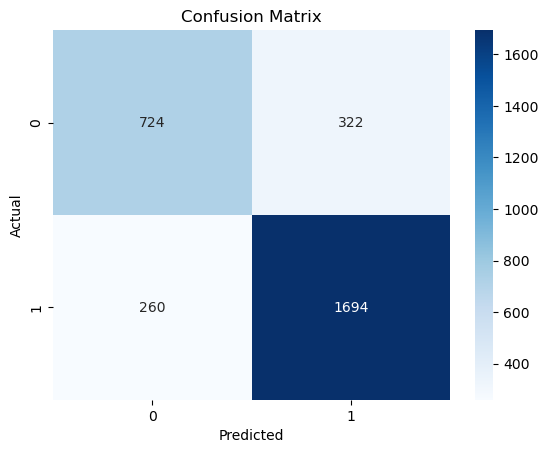

In [41]:
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')

plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix')
plt.show()

In [42]:
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.74      0.69      0.71      1046
           1       0.84      0.87      0.85      1954

    accuracy                           0.81      3000
   macro avg       0.79      0.78      0.78      3000
weighted avg       0.80      0.81      0.80      3000



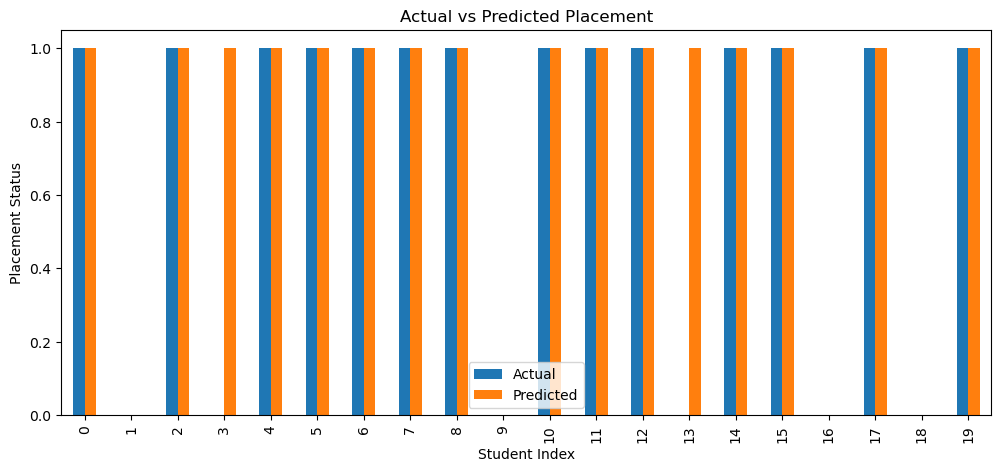

In [43]:
result = pd.DataFrame({
    'Actual': y_test.values,
    'Predicted': y_pred
})

result.head(20).plot(kind='bar', figsize=(12,5))

plt.title('Actual vs Predicted Placement')
plt.xlabel('Student Index')
plt.ylabel('Placement Status')
plt.show()

In [44]:
print(X.shape)
print(X.columns)

(15000, 48)
Index(['Age', 'CGPA', 'Attendance_Percentage', 'DSA_Problems_Solved',
       'Aptitude_Score', 'Communication_Score', 'Projects_Count',
       'Internships_Count', 'Certifications_Count',
       'Open_Source_Contributions', 'GitHub_Contributions',
       'LinkedIn_Activity_Score', 'Hackathons_Participated',
       'Competitive_Programming_Rating', 'Study_Hours_Per_Week',
       'Soft_Skills_Score', 'Extracurricular_Activities', 'Gender_Male',
       'Gender_Other', 'State_Assam', 'State_Bihar', 'State_Chhattisgarh',
       'State_Delhi', 'State_Gujarat', 'State_Haryana', 'State_Jharkhand',
       'State_Karnataka', 'State_Kerala', 'State_Madhya Pradesh',
       'State_Maharashtra', 'State_Odisha', 'State_Punjab', 'State_Rajasthan',
       'State_Tamil Nadu', 'State_Telangana', 'State_Uttar Pradesh',
       'State_Uttarakhand', 'State_West Bengal', 'Branch_CSE',
       'Branch_Chemical', 'Branch_Civil', 'Branch_ECE', 'Branch_EEE',
       'Branch_IT', 'Branch_Mechanical', 'Co

In [45]:
import joblib

joblib.dump(model, 'placement_model.pkl')

joblib.dump(scaler, 'placement_scaler.pkl')

['placement_scaler.pkl']

In [46]:
new_student = pd.DataFrame(0, index=[0], columns=X.columns)

# Numerical Features
new_student['Age'] = 22
new_student['CGPA'] = 8.5
new_student['Attendance_Percentage'] = 85
new_student['DSA_Problems_Solved'] = 200
new_student['Aptitude_Score'] = 80
new_student['Communication_Score'] = 85
new_student['Projects_Count'] = 3
new_student['Internships_Count'] = 2
new_student['Certifications_Count'] = 4
new_student['Open_Source_Contributions'] = 100
new_student['GitHub_Contributions'] = 300
new_student['LinkedIn_Activity_Score'] = 80
new_student['Hackathons_Participated'] = 3
new_student['Competitive_Programming_Rating'] = 1500
new_student['Study_Hours_Per_Week'] = 30
new_student['Soft_Skills_Score'] = 85
new_student['Extracurricular_Activities'] = 3

# Categorical Features
new_student['Gender_Male'] = 1
new_student['State_Maharashtra'] = 1
new_student['Branch_CSE'] = 1
new_student['College_Tier_Tier-2'] = 1
new_student['Leadership_Experience_Yes'] = 1

In [47]:
new_student_scaled = scaler.transform(new_student)

In [48]:
prediction = model.predict(new_student_scaled)

if prediction[0] == 1:
    print("Student is likely to be Placed")
else:
    print("Student is likely to be Not Placed")

Student is likely to be Placed


In [49]:
probability = model.predict_proba(new_student_scaled)

print("Not Placed Probability:", probability[0][0] * 100, "%")
print("Placed Probability:", probability[0][1] * 100, "%")

Not Placed Probability: 1.373490036152758 %
Placed Probability: 98.62650996384724 %
